# Лабораторная работа №3: объяснимость модели (SHAP, LIME) и проверка на новых данных (дрейф)

**Тема №23:** Анализ и прогноз погоды — *«Погода как знак и алгоритм»*

Материалы лаб. №3 (`docs/17_10_26_LAB_3__XAI+6_FUN_DEC_BOUND`) задают следующий вопрос после границ решений: **«Модель решила — но почему?»** и **«Можно ли доверять её прогнозу для новых данных?»**

| Часть | По материалам | На нашей задаче |
|---|---|---|
| A | SHAP: вклад признаков в прогноз — глобально и для одного случая | что заставляет модель ожидать дождь |
| B | LIME: локальная объясняющая модель вокруг одного случая | те же дни, другой метод |
| C | Сравнение SHAP и LIME: корреляция Пирсона, расхождения, пометка FLAGGED, экспорт | все 730 тестовых дней 2024–2025 |
| D | «Приложение с новыми данными»: сохранённая модель, новый CSV, прогнозы, карта PCA, **детектор дрейфа**, SHAP/LIME, экспорт, проверка по реальным меткам | **суточные данные Кишинёва за 2026 год** (01.01 – 19.10.2026), которые модель никогда не видела |

Модель — Random Forest из ноутбука 02 (обучена на 2015–2022), данные — из хранилища PostgreSQL.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
from lime.lime_tabular import LimeTabularExplainer
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from db import load_dataset, load_daily
from features import FEATURES, FEATURE_NAMES_RU, TARGET, RAIN_MM, compute_features
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, average_precision_score

warnings.filterwarnings("ignore")
FIG = ROOT / "figures"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
C_DRY, C_WET, C_POS, C_NEG = "#E0A030", "#2B6CB0", "#C0392B", "#2E8B57"
SEED = 42
RU = [FEATURE_NAMES_RU[f] for f in FEATURES]

def save(name):
    plt.savefig(FIG / f"{name}.png"); plt.show()

data = load_dataset("chisinau")
train = data[data.date.dt.year <= 2022]; valid = data[data.date.dt.year == 2023]; test = data[data.date.dt.year >= 2024].reset_index(drop=True)
bundle = joblib.load(ROOT / "models" / "baseline_model.joblib")
rf, THR = bundle["model"], bundle["threshold"]
X_te, y_te = test[FEATURES], test[TARGET].to_numpy()
p_te = rf.predict_proba(X_te)[:, 1]
predict_fn = lambda a: rf.predict_proba(pd.DataFrame(a, columns=FEATURES))
print(f"Модель: {bundle['model_name']}, порог {THR:.2f}; тест: {len(test)} дней")

Модель: Random Forest, порог 0.23; тест: 730 дней


---
# A. SHAP — вклад признаков в прогноз

**SHAP** (SHapley Additive exPlanations) — метод из кооперативной теории игр: прогноз «раскладывается» на сумму вкладов признаков:
$$P(\text{дождь}) = \underbrace{\phi_0}_{\text{средний прогноз}} + \sum_{j=1}^{26} \phi_j$$
Положительный вклад $\phi_j$ подталкивает прогноз к «дождю», отрицательный — к «сухо». Для деревьев решений (`TreeExplainer`) вклады вычисляются **точно**, и в сумме они дают ровно вероятность модели.

In [2]:
explainer = shap.TreeExplainer(rf)
sv = np.asarray(explainer.shap_values(X_te))
sv = sv[..., 1] if sv.ndim == 3 else sv          # contributions to P(rain)
ev = explainer.expected_value
base = float(ev[1] if np.ndim(ev) else ev)
print(f"Средний прогноз модели (база SHAP): {base:.3f}")
print(f"Проверка аддитивности: max |база + сумма вкладов − вероятность| = {np.abs(base + sv.sum(1) - p_te).max():.1e}")

Средний прогноз модели (база SHAP): 0.243
Проверка аддитивности: max |база + сумма вкладов − вероятность| = 1.8e-15


## A.1 Глобальная картина: какие признаки важны для всех прогнозов

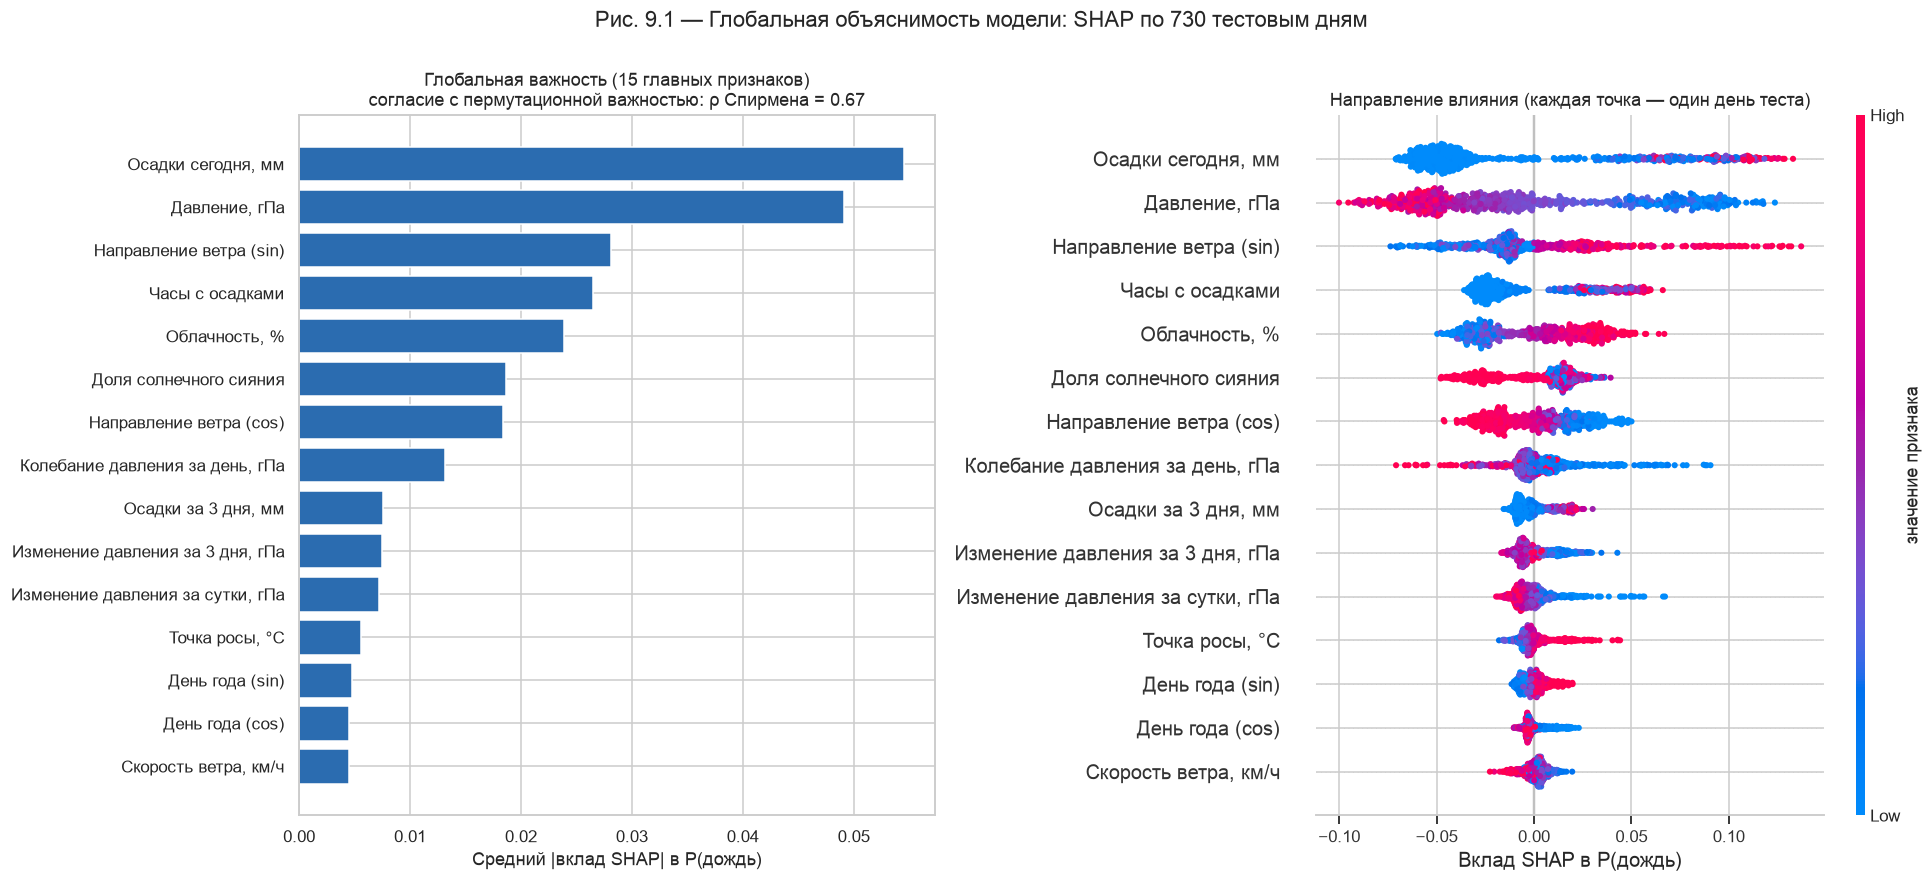

In [3]:
mean_abs = pd.Series(np.abs(sv).mean(0), index=RU).sort_values()
perm = permutation_importance(rf, X_te, y_te, scoring="average_precision", n_repeats=10, random_state=SEED, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=RU)
rho = stats.spearmanr(mean_abs.reindex(RU), perm_s.reindex(RU)).statistic

fig = plt.figure(figsize=(18, 8))
ax1 = fig.add_subplot(1, 2, 1)
ax1.barh(mean_abs.index[-15:], mean_abs.values[-15:], color=C_WET)
ax1.set(xlabel="Средний |вклад SHAP| в P(дождь)", title=f"Глобальная важность (15 главных признаков)\nсогласие с пермутационной важностью: ρ Спирмена = {rho:.2f}")
plt.sca(fig.add_subplot(1, 2, 2))
shap.summary_plot(sv, X_te.set_axis(RU, axis=1), max_display=15, show=False, plot_size=None, color_bar_label="значение признака")
plt.gca().set_title("Направление влияния (каждая точка — один день теста)")
plt.gca().set_xlabel("Вклад SHAP в P(дождь)")
fig.suptitle("Рис. 9.1 — Глобальная объяснимость модели: SHAP по 730 тестовым дням", y=1.0)
plt.tight_layout(); save("fig_9_1_shap_global")

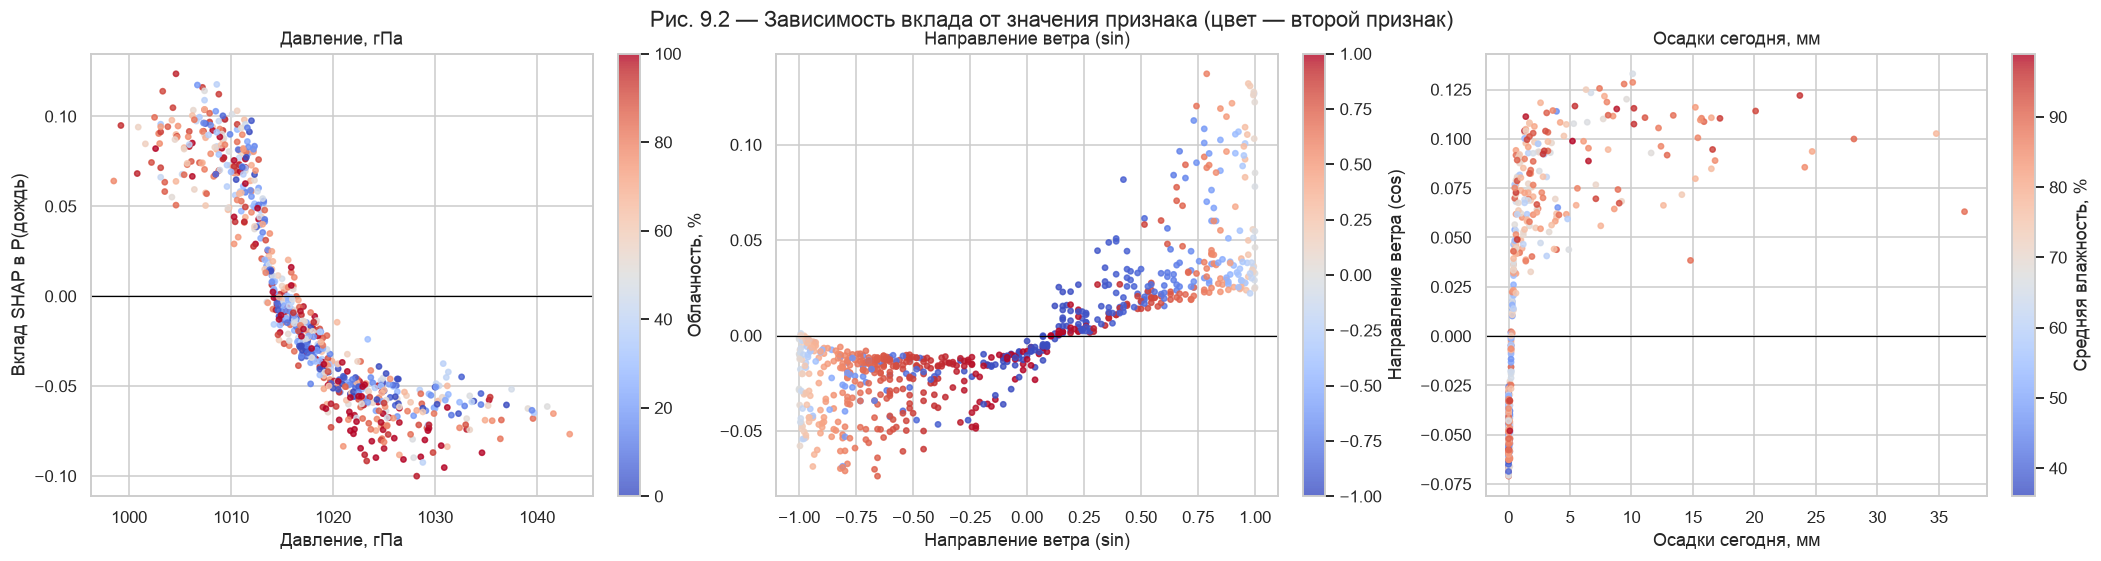

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), layout="constrained")
for ax, (f, cf) in zip(axes, [("pressure_msl_mean", "cloud_cover_mean"), ("wind_dir_sin", "wind_dir_cos"), ("precipitation_sum", "relative_humidity_2m_mean")]):
    j = FEATURES.index(f)
    sc_ = ax.scatter(X_te[f], sv[:, j], c=X_te[cf], cmap="coolwarm", s=12, alpha=0.8)
    plt.colorbar(sc_, ax=ax, label=FEATURE_NAMES_RU[cf])
    ax.axhline(0, color="black", lw=0.8)
    ax.set(xlabel=FEATURE_NAMES_RU[f], ylabel="Вклад SHAP в P(дождь)" if ax is axes[0] else "", title=FEATURE_NAMES_RU[f])
fig.suptitle("Рис. 9.2 — Зависимость вклада от значения признака (цвет — второй признак)", y=1.03)
save("fig_9_2_shap_dependence")

**Интерпретация.**
- **SHAP раскладывает каждую вероятность точно:** база (средний прогноз) 0.243 + сумма вкладов 26 признаков = вероятность модели, ошибка аддитивности порядка 10⁻¹⁵ (ошибка округления). Поэтому вклад SHAP можно читать прямо в единицах вероятности дождя.
- **Главные признаки (рис. 9.1):** осадки сегодня и давление — с большим отрывом; дальше направление ветра (sin), часы с осадками и облачность. Это совпадает с важностью Random Forest из ноутбука 02 и с метеорологией.
- **Направление влияния (правая панель):** низкое давление, дождь сегодня, большая облачность и ветер с востока (sin > 0) тянут прогноз к дождю; высокое давление и солнечный день — к сухой погоде.
- **Рис. 9.2 показывает форму зависимости:** вклад давления почти ступенчатый — около 1012–1015 гПа он меняет знак, ниже 1010 гПа даёт до +0.10 к вероятности, выше 1020 гПа — около −0.05…−0.10. Для осадков сегодня важен сам факт дождя: переход от 0 к ≈ 1–2 мм добавляет ≈ +0.05…+0.10, дальше рост почти прекращается.
- **Согласие с перестановочной важностью — только умеренное (ρ = 0.67).** Это не противоречие: SHAP измеряет, насколько признак двигает прогноз, а перестановка — насколько падает качество без него. Коррелированные признаки (давление и его изменения, облачность и солнечное сияние) делят между собой важность по-разному. Поэтому мы опираемся на оба метода, а не на один.

---
# B. Локальные объяснения одного прогноза: SHAP и LIME

**LIME** (Local Interpretable Model-agnostic Explanations) работает иначе: вокруг выбранного дня генерирует тысячи «похожих» искусственных дней, смотрит на ответы модели и подгоняет к ним простую линейную модель. Её коэффициенты и есть объяснение. LIME **не знает устройства модели** (подходит для любой), но результат зависит от случайных возмущений и настроек.

Берём три показательных дня теста: **верно предсказанный дождь**, **ложную тревогу** и **пропущенный дождь**.

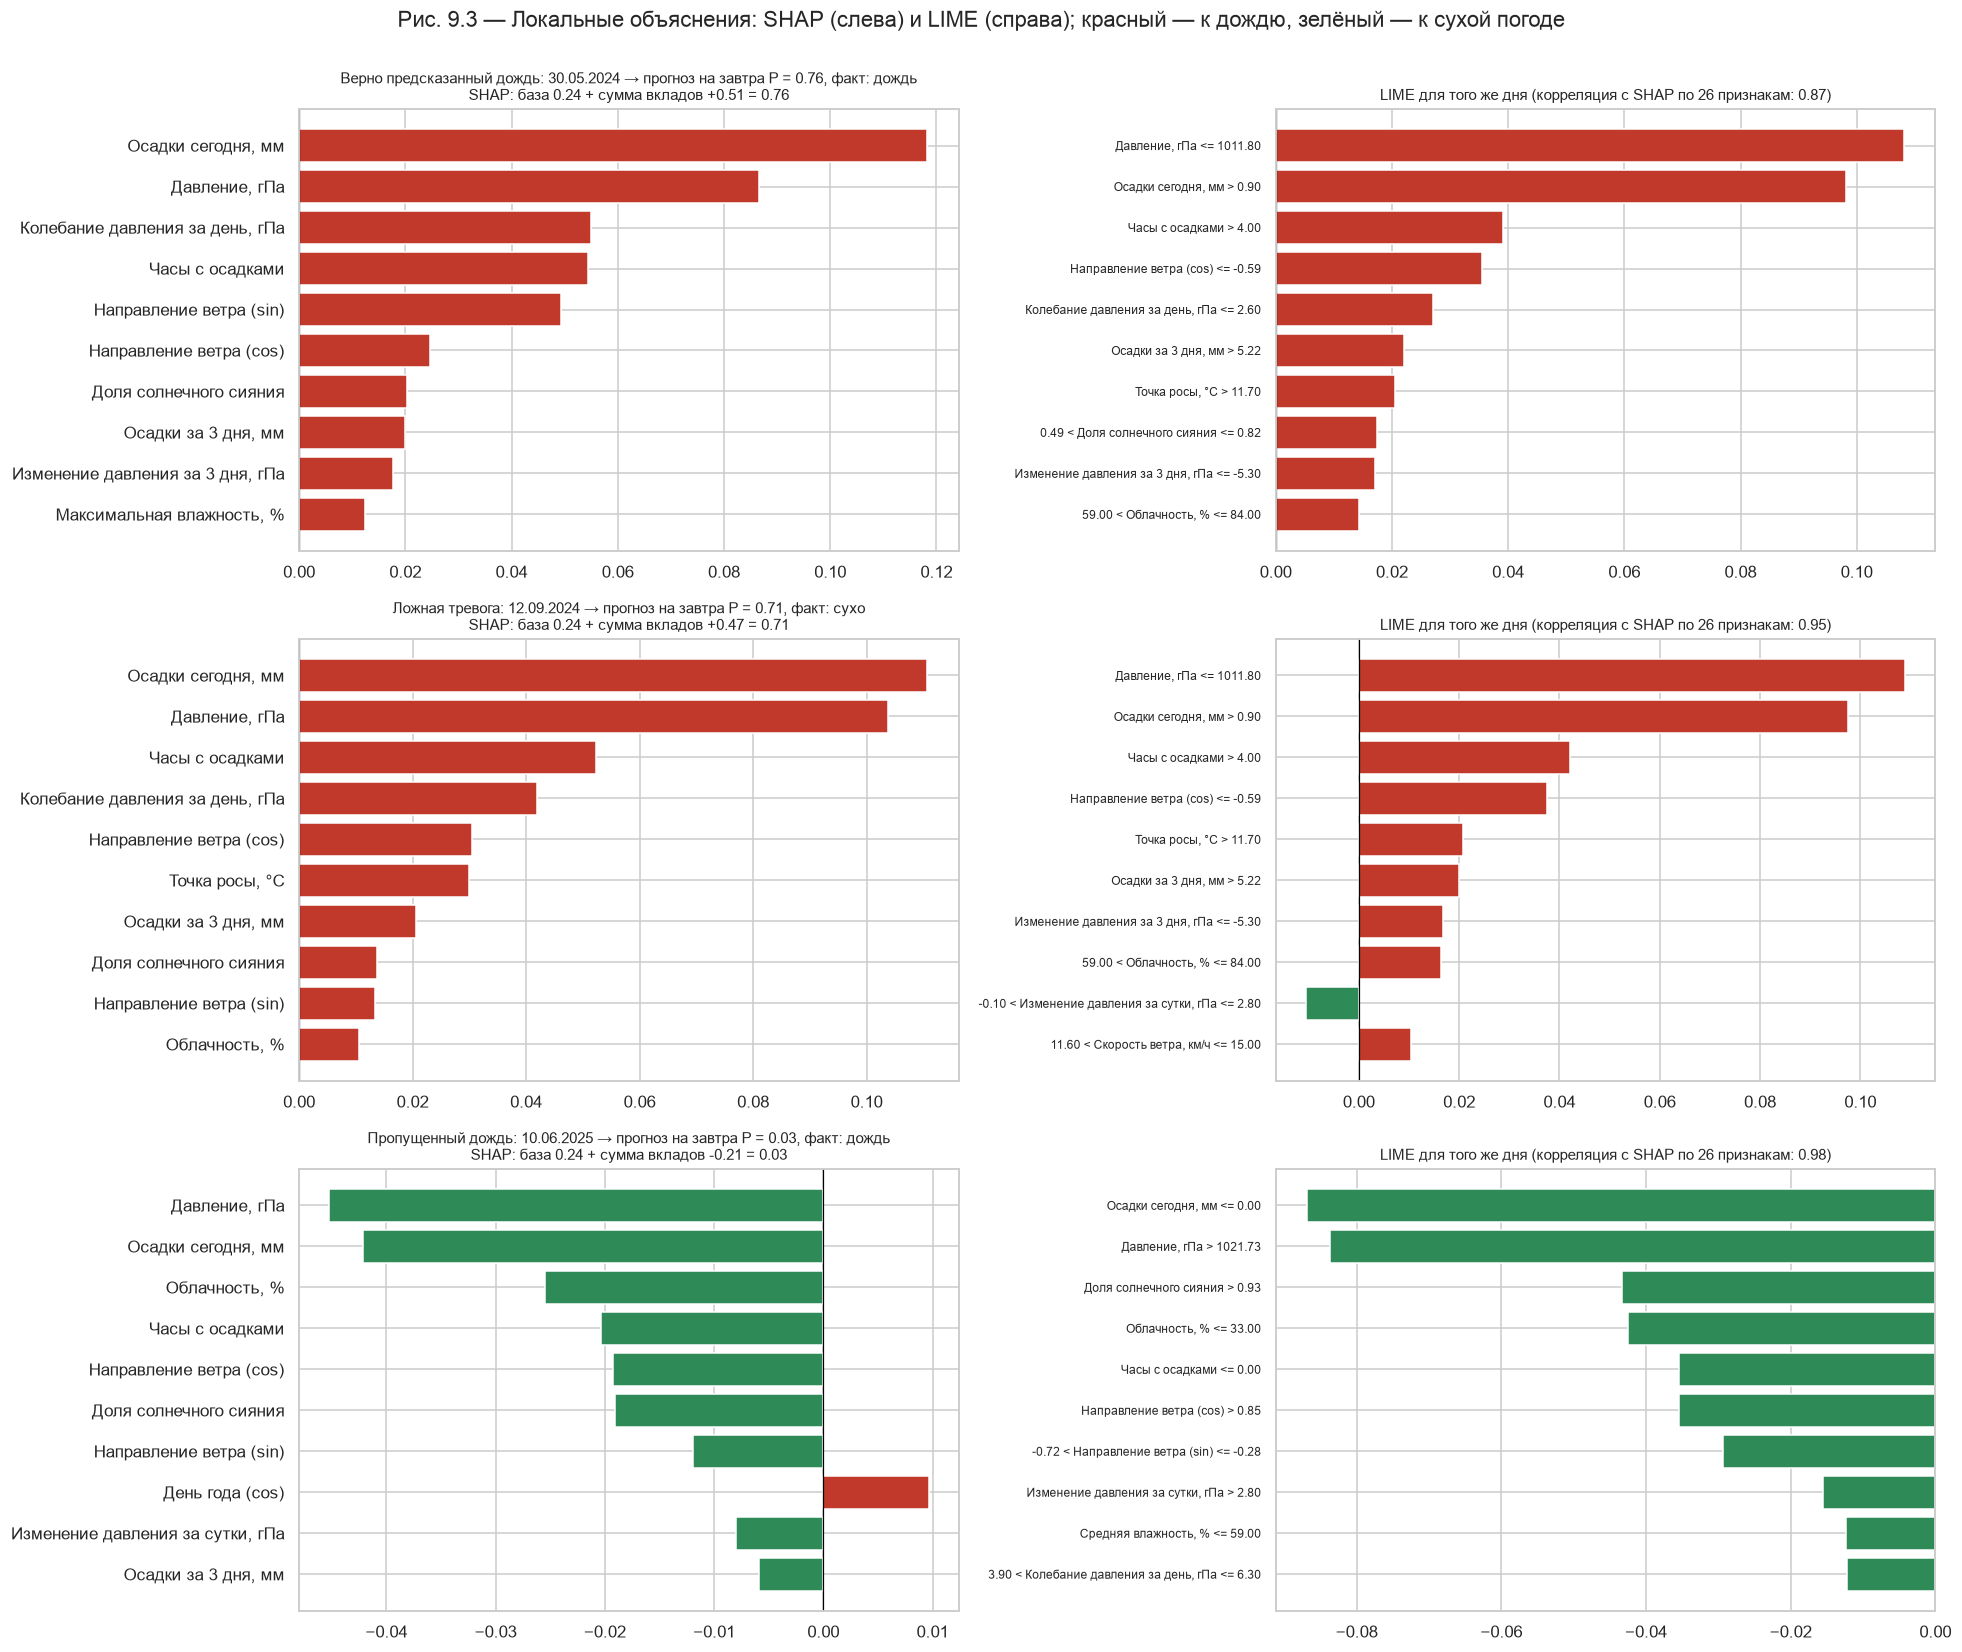

,Случай,Дата,P(дождь),Факт
0,Верно предсказанный дождь,2024-05-30,0.755,дождь
1,Ложная тревога,2024-09-12,0.709,сухо
2,Пропущенный дождь,2025-06-10,0.033,дождь


In [5]:
lime_exp = LimeTabularExplainer(train[FEATURES].to_numpy(), feature_names=FEATURES, class_names=["сухо", "дождь"],
                                discretize_continuous=True, mode="classification", random_state=SEED)

def lime_vector(x, seed=SEED, num_samples=5000):
    lime_exp.random_state = np.random.RandomState(seed)
    e = lime_exp.explain_instance(np.asarray(x, dtype=float), predict_fn, num_features=len(FEATURES), num_samples=num_samples)
    v = np.zeros(len(FEATURES))
    for j, w in e.as_map()[1]:
        v[j] = w
    return v, e

pred = (p_te >= THR).astype(int)
cases = {
    "Верно предсказанный дождь": int(np.argmax(np.where((pred == 1) & (y_te == 1), p_te, -1))),
    "Ложная тревога": int(np.argmax(np.where((pred == 1) & (y_te == 0), p_te, -1))),
    "Пропущенный дождь": int(np.argmin(np.where((pred == 0) & (y_te == 1), p_te, 2))),
}
fig, axes = plt.subplots(3, 2, figsize=(18, 15))
for r, (title, i) in enumerate(cases.items()):
    lv, e = lime_vector(X_te.iloc[i])
    s = pd.Series(sv[i], index=RU); top = s.abs().sort_values().index[-10:]
    axes[r, 0].barh(top, s[top], color=np.where(s[top] > 0, C_POS, C_NEG))
    axes[r, 0].axvline(0, color="black", lw=0.8)
    axes[r, 0].set_title(f"{title}: {test.date[i]:%d.%m.%Y} → прогноз на завтра P = {p_te[i]:.2f}, факт: {'дождь' if y_te[i] else 'сухо'}\n"
                         f"SHAP: база {base:.2f} + сумма вкладов {sv[i].sum():+.2f} = {p_te[i]:.2f}", fontsize=10)
    lst = e.as_list(label=1)[:10][::-1]
    labels = []
    for cond, _ in lst:
        for f in sorted(FEATURES, key=len, reverse=True):
            if f in cond:
                cond = cond.replace(f, FEATURE_NAMES_RU[f]); break
        labels.append(cond)
    axes[r, 1].barh(labels, [w for _, w in lst], color=[C_POS if w > 0 else C_NEG for _, w in lst])
    axes[r, 1].axvline(0, color="black", lw=0.8)
    corr = np.corrcoef(sv[i] / np.abs(sv[i]).sum(), lv / np.abs(lv).sum())[0, 1]
    axes[r, 1].set_title(f"LIME для того же дня (корреляция с SHAP по 26 признакам: {corr:.2f})", fontsize=10)
    axes[r, 1].tick_params(axis="y", labelsize=8)
fig.suptitle("Рис. 9.3 — Локальные объяснения: SHAP (слева) и LIME (справа); красный — к дождю, зелёный — к сухой погоде", y=1.0)
plt.tight_layout(); save("fig_9_3_local_shap_lime")
pd.DataFrame({"Случай": list(cases), "Дата": [test.date[i].date() for i in cases.values()],
              "P(дождь)": [round(p_te[i], 3) for i in cases.values()], "Факт": ["дождь" if y_te[i] else "сухо" for i in cases.values()]})

**Интерпретация (рис. 9.3).**
- **Верно предсказанный дождь 30.05.2024 (P = 0.76):** база 0.24 + 0.51. Главные вклады — дождь сегодня (+0.12) и низкое давление (+0.09), затем колебание давления и часы с осадками. LIME называет те же признаки, но на первое место ставит давление (правило «давление ≤ 1011.8»). Корреляция SHAP–LIME 0.87.
- **Ложная тревога 12.09.2024 (P = 0.71):** объяснение почти такое же, как у верного прогноза: дождь сегодня, низкое давление, много часов с осадками. Модель **рассуждала правильно** — по суточным данным этот день выглядел как типичный дождливый, а дождь на следующий день просто не случился. Такие ошибки объяснимость не устраняет, она только показывает, что ошибка не в логике модели, а в недостатке информации. Корреляция 0.95.
- **Пропущенный дождь 10.06.2025 (P = 0.03):** все главные признаки голосуют против дождя — высокое давление (> 1021.7 гПа), сухой солнечный день, облачность ≤ 33 %. Это типичная летняя конвективная гроза: она развивается за несколько часов и по суточным средним не видна. Единственный вклад «к дождю» — день года (лето). Корреляция 0.98.
- **Вывод:** объяснения позволяют отличить «модель ошиблась в логике» от «модели не хватило данных». У нас оба вида ошибок — второго типа. Сделали локальные объяснения, **потому что** глобальная важность не говорит, почему ошибся конкретный день.

---
# C. SHAP против LIME: насколько согласны объяснения?

Как в приложении из материалов: для каждого дня вклады SHAP и LIME **нормируются отдельно** (делением на сумму модулей), затем считаются
- **корреляция Пирсона** между двумя векторами из 26 вкладов;
- **абсолютная разница** вкладов по каждому признаку.

День помечается **FLAGGED** (требует проверки), если корреляция ниже порога **0.5** или хотя бы по одному признаку разница больше **0.15**. Пороги — параметры анализа, а не универсальные границы.

In [6]:
CORR_THR, DIFF_THR = 0.5, 0.15
L = np.zeros_like(sv)
for i in range(len(test)):
    L[i] = lime_vector(X_te.iloc[i])[0]
Sn = sv / np.abs(sv).sum(1, keepdims=True)
Ln = L / np.abs(L).sum(1, keepdims=True)
corr = np.array([np.corrcoef(Sn[i], Ln[i])[0, 1] for i in range(len(test))])
diff = np.abs(Sn - Ln)
flag_corr, flag_diff = corr < CORR_THR, diff.max(1) > DIFF_THR
flagged = flag_corr | flag_diff
summary = pd.DataFrame({"Дата": test.date.dt.date, "P(дождь)": p_te.round(3), "Прогноз": pred, "Факт": y_te,
                        "Корреляция SHAP–LIME": corr.round(3), "Макс. разница": diff.max(1).round(3),
                        "Статус": np.where(flagged, "FLAGGED", "OK"),
                        "Причина": np.select([flag_corr & flag_diff, flag_corr, flag_diff], ["корреляция и разница", "низкая корреляция", "большая разница"], ""),
                        "Признаки с большой разницей": [", ".join(FEATURE_NAMES_RU[FEATURES[j]] for j in np.where(diff[i] > DIFF_THR)[0]) for i in range(len(test))]})
print(f"Медианная корреляция SHAP–LIME: {np.median(corr):.2f}; FLAGGED: {flagged.sum()} из {len(test)} дней ({flagged.mean():.0%})")
print(summary["Причина"].replace("", "—").value_counts().to_string())

Медианная корреляция SHAP–LIME: 0.92; FLAGGED: 74 из 730 дней (10%)
Причина
—                       656
большая разница          58
корреляция и разница     16


In [7]:
# stability of LIME itself: the same day explained with 5 different random seeds
idx = np.random.default_rng(SEED).choice(len(test), 25, replace=False)
self_corr = []
for i in idx:
    vs = [lime_vector(X_te.iloc[i], seed=s)[0] for s in range(5)]
    vs = [v / np.abs(v).sum() for v in vs]
    self_corr += [np.corrcoef(vs[a], vs[b])[0, 1] for a in range(5) for b in range(a + 1, 5)]
shap_lime_rank = stats.spearmanr(np.abs(Sn).mean(0), np.abs(Ln).mean(0)).statistic
print(f"LIME сам с собой (5 случайных зёрен, 25 дней): медианная корреляция {np.median(self_corr):.2f}, минимум {np.min(self_corr):.2f}")
print(f"Глобально (средние модули вкладов по 730 дням): ρ Спирмена SHAP–LIME = {shap_lime_rank:.2f}")
often = pd.Series((diff > DIFF_THR).sum(0), index=RU).sort_values(ascending=False)
often[often > 0].head(8).to_frame("Дней с разницей > порога")

LIME сам с собой (5 случайных зёрен, 25 дней): медианная корреляция 0.99, минимум 0.93
Глобально (средние модули вкладов по 730 дням): ρ Спирмена SHAP–LIME = 0.97


,Дней с разницей > порога
"Осадки сегодня, мм",56
"Давление, гПа",14
"Колебание давления за день, гПа",3
Направление ветра (sin),2
"Изменение давления за сутки, гПа",1


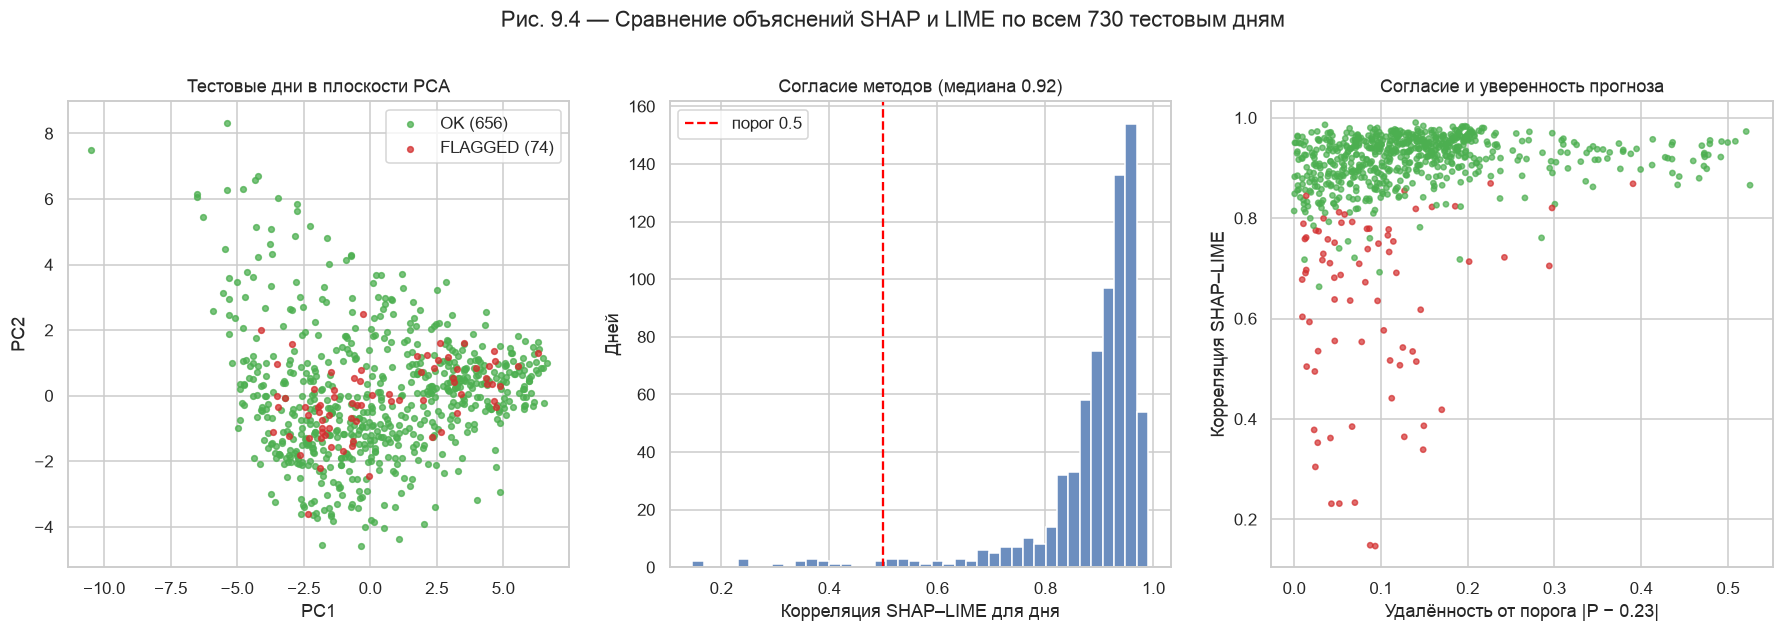

In [8]:
pca = PCA(2, random_state=SEED).fit(StandardScaler().fit(train[FEATURES]).transform(train[FEATURES]))
sc_te = StandardScaler().fit(train[FEATURES])
Z = pca.transform(sc_te.transform(X_te))
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for st_, col in [("OK", "#4CAF50"), ("FLAGGED", "#D32F2F")]:
    m = summary["Статус"] == st_
    axes[0].scatter(Z[m, 0], Z[m, 1], s=14, color=col, alpha=0.75, label=f"{st_} ({m.sum()})")
axes[0].set(xlabel="PC1", ylabel="PC2", title="Тестовые дни в плоскости PCA"); axes[0].legend()
axes[1].hist(corr, bins=40, color="#6C8EBF"); axes[1].axvline(CORR_THR, color="red", ls="--", label=f"порог {CORR_THR}")
axes[1].set(xlabel="Корреляция SHAP–LIME для дня", ylabel="Дней", title=f"Согласие методов (медиана {np.median(corr):.2f})"); axes[1].legend()
axes[2].scatter(np.abs(p_te - THR), corr, c=np.where(flagged, "#D32F2F", "#4CAF50"), s=12, alpha=0.7)
axes[2].set(xlabel="Удалённость от порога |P − 0.23|", ylabel="Корреляция SHAP–LIME", title="Согласие и уверенность прогноза")
fig.suptitle("Рис. 9.4 — Сравнение объяснений SHAP и LIME по всем 730 тестовым дням", y=1.03)
save("fig_9_4_shap_vs_lime")

In [9]:
detail = pd.DataFrame({"Дата": np.repeat(test.date.dt.date.to_numpy(), len(FEATURES)), "Признак": np.tile(RU, len(test)),
                       "Значение": X_te.to_numpy().ravel().round(3), "SHAP (норм.)": Sn.ravel().round(4), "LIME (норм.)": Ln.ravel().round(4),
                       "Разница": diff.ravel().round(4)})
detail["Состояние признака"] = np.where(detail["Разница"] > DIFF_THR, "расхождение", "согласие")
detail.to_csv(ROOT / "data" / "processed" / "xai_shap_lime_detail.csv", index=False)
summary.to_csv(ROOT / "data" / "processed" / "xai_shap_lime_summary.csv", index=False)
print("Экспорт: data/processed/xai_shap_lime_detail.csv (подробно), data/processed/xai_shap_lime_summary.csv (сводка по дням)")
summary[summary["Статус"] == "FLAGGED"].head(8)

Экспорт: data/processed/xai_shap_lime_detail.csv (подробно), data/processed/xai_shap_lime_summary.csv (сводка по дням)


,Дата,P(дождь),Прогноз,Факт,Корреляция SHAP–LIME,Макс. разница,Статус,Причина,Признаки с большой разницей
3,2024-01-04,0.315,1,0,0.738,0.219,FLAGGED,большая разница,"Осадки сегодня, мм"
5,2024-01-06,0.389,1,1,0.822,0.171,FLAGGED,большая разница,"Давление, гПа"
10,2024-01-11,0.245,1,0,0.504,0.224,FLAGGED,большая разница,"Осадки сегодня, мм"
20,2024-01-21,0.134,0,0,0.635,0.266,FLAGGED,большая разница,"Осадки сегодня, мм"
23,2024-01-24,0.255,1,1,0.776,0.164,FLAGGED,большая разница,"Осадки сегодня, мм"
32,2024-02-02,0.163,0,0,0.385,0.262,FLAGGED,корреляция и разница,"Осадки сегодня, мм"
39,2024-02-09,0.357,1,0,0.855,0.178,FLAGGED,большая разница,"Осадки сегодня, мм"
51,2024-02-21,0.176,0,0,0.687,0.234,FLAGGED,большая разница,"Осадки сегодня, мм"


**Интерпретация (рис. 9.4).**
- **В целом методы согласны:** медианная корреляция SHAP–LIME по 730 дням — 0.92, глобальный порядок признаков почти одинаковый (ρ Спирмена = 0.97).
- **FLAGGED — 74 дня из 730 (10 %).** Ни один не помечен только по низкой корреляции: 58 дней — только из-за большой разницы по признаку (> 0.15), 16 — по обоим порогам.
- **Главный источник расхождений — один признак:** «осадки сегодня» (56 дней из 74). Причина в устройстве LIME: он **дискретизирует** признак по квартилям, а у осадков больше половины значений — ровно 0. Получается грубое правило «осадки > 0.9 мм», а SHAP работает с реальной формой зависимости (рис. 9.2). Это расхождение методов, а не ошибка модели.
- **LIME стабилен сам с собой:** при 5 разных случайных зёрнах медианная корреляция 0.99 (минимум 0.93). Значит, расхождения с SHAP систематические (из-за дискретизации), а не случайные.
- **Расхождения сосредоточены у порога (правая панель):** у FLAGGED-дней медианная удалённость от порога 0.073 (у остальных 0.121), 64 % из них ближе 0.1 к порогу (у остальных 40 %), доля ошибок 37.8 % против 30.2 %. То есть несогласие объяснений — дополнительный признак **неуверенного прогноза**, совпадающий с чувствительными точками из ноутбука 07.
- **Мера:** таблица по всем дням с пометкой FLAGGED и причиной выгружена в CSV — эти дни разбираются вручную (как в приложении преподавателя).

## C.2 Метод из исправленной версии приложения (`docs/DEC_XAI`)

Преподаватель выложил исправленную версию приложения (`app_dec_xai_CORRECTED.py`). Отличия от первой версии, на которую опирается раздел C:

| | Раздел C (наш вариант) | Исправленная версия (DEC_XAI) |
|---|---|---|
| Нормировка вкладов дня | деление на **сумму модулей** (доли общего вклада) | деление на **максимальный модуль** (главный признак = ±1) |
| Флаг признака | разница > 0.15 | разница > **0.5** («БОЛЬШОЕ РАСХОЖДЕНИЕ») |
| Флаг дня | корреляция < 0.5 или флаг хотя бы у одного признака | то же («НИЗКОЕ СОГЛАСИЕ» по корреляции) |
| Интерпретация разницы | — | 4 уровня: < 0.2 сильное согласие; < 0.5 умеренная (ограничения LIME); < 0.8 большая (взаимодействия признаков); ≥ 0.8 очень большая (нестабильность) |
| Корреляция Пирсона | всегда считается | не определена (NaN), если один из векторов постоянен |
| LIME | вклады по индексам признаков класса «дождь» | то же: `labels=(1,)`, `local_exp[1]` по индексам (у нас так и было) |

Корреляция Пирсона **не зависит от масштаба**, поэтому смена нормировки меняет только флаги по разнице. Применяем метод DEC_XAI к тем же 730 дням и сравниваем: сколько дней помечено, каких, и какой вариант полезнее.

In [10]:
DIFF_THR_MAX = 0.5
LEVELS4 = ["сильное согласие", "умеренная разница (ограничения LIME)", "большая разница (взаимодействия)", "очень большая разница (нестабильность)"]

def norm_max(V):
    m = np.abs(V).max(1, keepdims=True)
    return np.divide(V, m, out=np.zeros_like(V), where=m > 0)

def safe_corr(a, b):
    return np.nan if (np.std(a) == 0 or np.std(b) == 0) else float(np.corrcoef(a, b)[0, 1])

def level4(d):
    return np.select([d < 0.2, d < 0.5, d < 0.8], LEVELS4[:3], LEVELS4[3])

Sm, Lm = norm_max(sv), norm_max(L)
corr_m = np.array([safe_corr(Sm[i], Lm[i]) for i in range(len(test))])
diff_m = np.abs(Sm - Lm)
fc_m, fd_m = corr_m < CORR_THR, diff_m.max(1) > DIFF_THR_MAX
flag_m = fc_m | fd_m
print(f"Корреляция не изменилась: max |r(max) − r(сумма)| = {np.nanmax(np.abs(corr_m - corr)):.1e}; NaN-корреляций: {np.isnan(corr_m).sum()}")

err = pred != y_te
dist = np.abs(p_te - THR)
def describe(flag, fc, fd, name):
    return {"Вариант": name, "FLAGGED": int(flag.sum()), "Доля": flag.mean(), "Только корреляция": int((fc & ~fd).sum()),
            "Только разница": int((fd & ~fc).sum()), "Оба": int((fc & fd).sum()),
            "Медиана |P − порог| у FLAGGED": np.median(dist[flag]), "Медиана у остальных": np.median(dist[~flag]),
            "Ошибок среди FLAGGED": err[flag].mean(), "Ошибок среди остальных": err[~flag].mean()}
cmp = pd.DataFrame([describe(flagged, flag_corr, flag_diff, "Раздел C: сумма модулей, порог 0.15"),
                    describe(flag_m, fc_m, fd_m, "DEC_XAI: максимум, порог 0.5")])
print(f"Пересечение: {int((flagged & flag_m).sum())} дней помечены обоими вариантами; "
      f"{int((flagged & ~flag_m).sum())} — только нашим; {int((flag_m & ~flagged).sum())} — только DEC_XAI")
cmp.round(3)

Корреляция не изменилась: max |r(max) − r(сумма)| = 8.9e-16; NaN-корреляций: 0
Пересечение: 72 дней помечены обоими вариантами; 2 — только нашим; 181 — только DEC_XAI


,Вариант,FLAGGED,Доля,Только корреляция,Только разница,Оба,Медиана |P − порог| у FLAGGED,Медиана у остальных,Ошибок среди FLAGGED,Ошибок среди остальных
0,"Раздел C: сумма модулей, порог 0.15",74,0.101,0,58,16,0.073,0.121,0.378,0.302
1,"DEC_XAI: максимум, порог 0.5",253,0.347,0,237,16,0.081,0.135,0.340,0.294


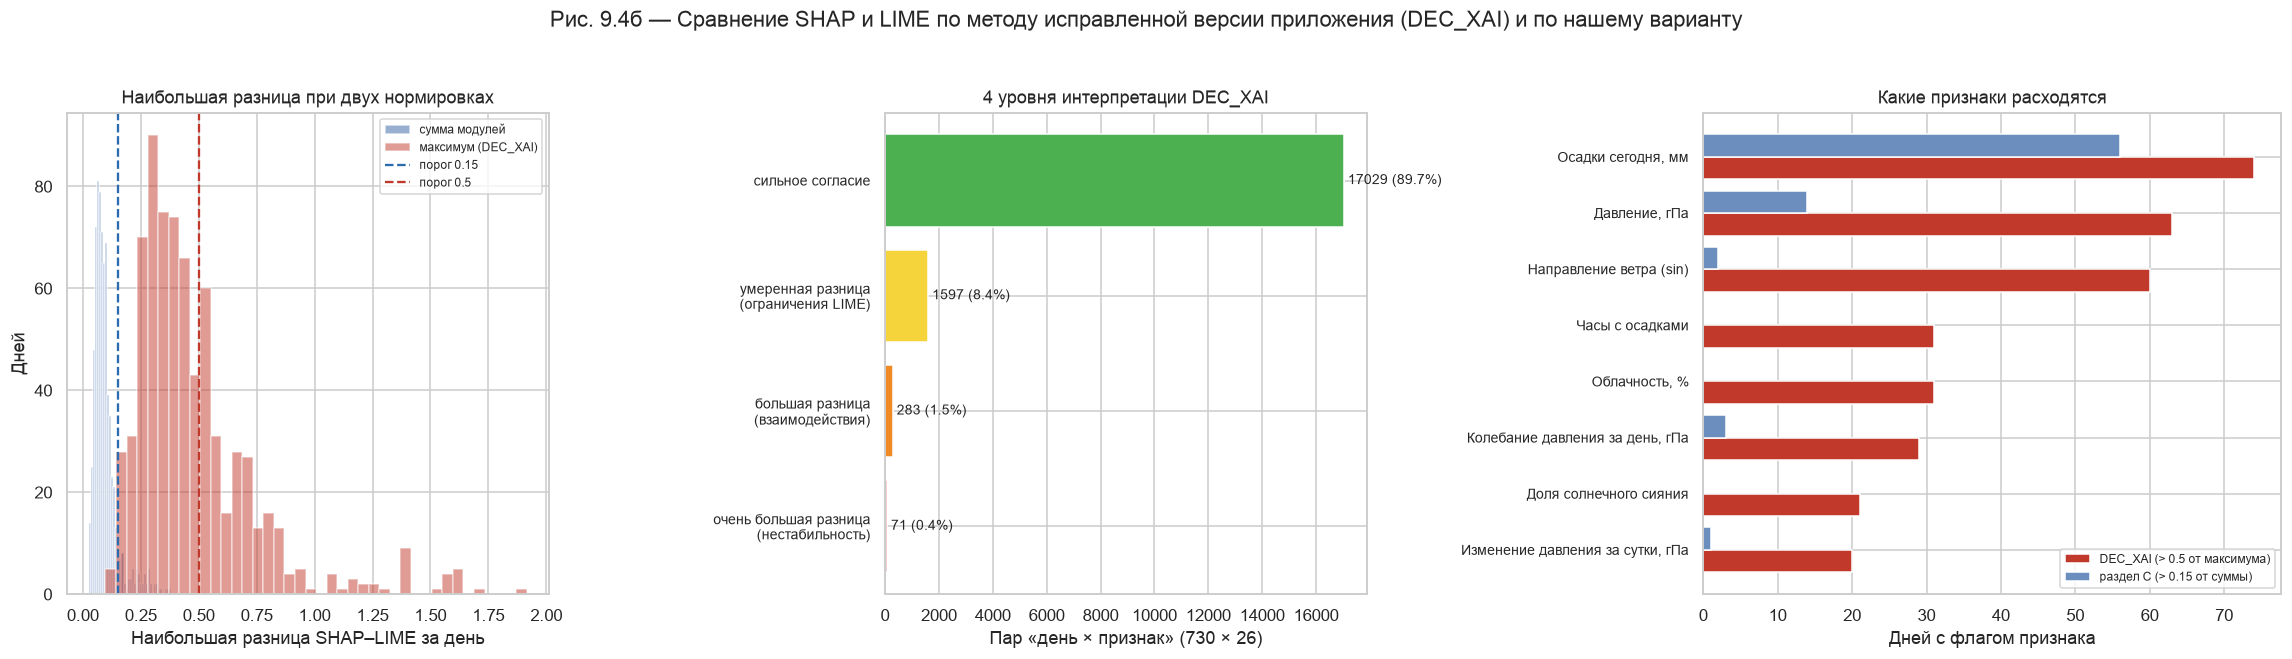

,Нормировка,Порог разницы,FLAGGED,Ошибок среди FLAGGED,Медиана |P − порог|
0,сумма модулей,0.10,244,0.381,0.087
1,сумма модулей,0.15,74,0.378,0.073
2,сумма модулей,0.20,45,0.289,0.067
3,сумма модулей,0.30,17,0.176,0.070
4,максимум (DEC_XAI),0.30,554,0.332,0.104
5,максимум (DEC_XAI),0.50,253,0.340,0.081
6,максимум (DEC_XAI),0.80,69,0.232,0.065
7,максимум (DEC_XAI),1.00,34,0.206,0.066


In [11]:
sens = []
for name_, D, thrs in [("сумма модулей", diff, [0.10, 0.15, 0.20, 0.30]), ("максимум (DEC_XAI)", diff_m, [0.3, 0.5, 0.8, 1.0])]:
    for t in thrs:
        f = (corr < CORR_THR) | (D.max(1) > t)
        sens.append({"Нормировка": name_, "Порог разницы": t, "FLAGGED": int(f.sum()), "Ошибок среди FLAGGED": err[f].mean(),
                     "Медиана |P − порог|": np.median(dist[f])})
sens = pd.DataFrame(sens)

fig, axes = plt.subplots(1, 3, figsize=(21, 5.8), gridspec_kw={"width_ratios": [1, 1, 1.2]})
axes[0].hist(diff.max(1), bins=40, color="#6C8EBF", alpha=0.7, label="сумма модулей")
axes[0].hist(diff_m.max(1), bins=40, color="#C0392B", alpha=0.5, label="максимум (DEC_XAI)")
axes[0].axvline(DIFF_THR, color="#2B6CB0", ls="--", label=f"порог {DIFF_THR}"); axes[0].axvline(DIFF_THR_MAX, color="#C0392B", ls="--", label=f"порог {DIFF_THR_MAX}")
axes[0].set(xlabel="Наибольшая разница SHAP–LIME за день", ylabel="Дней", title="Наибольшая разница при двух нормировках"); axes[0].legend(fontsize=8)
lv = pd.Series(level4(diff_m.ravel())).value_counts().reindex(LEVELS4)
axes[1].barh(range(4), lv.values, color=["#4CAF50", "#F5D33B", "#F08A24", "#D32F2F"])
axes[1].set_yticks(range(4)); axes[1].set_yticklabels([l.replace(" (", "\n(") for l in LEVELS4], fontsize=9); axes[1].invert_yaxis()
for k, v in enumerate(lv.values):
    axes[1].text(v, k, f" {v} ({v / lv.sum():.1%})", va="center", fontsize=9)
axes[1].set(xlabel="Пар «день × признак» (730 × 26)", title="4 уровня интерпретации DEC_XAI")
top_m = pd.Series((diff_m > DIFF_THR_MAX).sum(0), index=RU).sort_values()[-8:]
top_s = pd.Series((diff > DIFF_THR).sum(0), index=RU).reindex(top_m.index)
yy = np.arange(len(top_m))
axes[2].barh(yy - 0.2, top_m.values, height=0.4, color="#C0392B", label="DEC_XAI (> 0.5 от максимума)")
axes[2].barh(yy + 0.2, top_s.values, height=0.4, color="#6C8EBF", label="раздел C (> 0.15 от суммы)")
axes[2].set_yticks(yy); axes[2].set_yticklabels(top_m.index, fontsize=9)
axes[2].set(xlabel="Дней с флагом признака", title="Какие признаки расходятся"); axes[2].legend(fontsize=8)
fig.suptitle("Рис. 9.4б — Сравнение SHAP и LIME по методу исправленной версии приложения (DEC_XAI) и по нашему варианту", y=1.03)
plt.tight_layout(); save("fig_9_4b_dec_xai_normalization")
sens.round(3)

In [12]:
# export in the format of the corrected app: per feature (batch) and per day (summary), next to our columns
detail["SHAP (норм. max)"] = Sm.ravel().round(4)
detail["LIME (норм. max)"] = Lm.ravel().round(4)
detail["Разница (max)"] = diff_m.ravel().round(4)
detail["Интерпретация (DEC_XAI)"] = level4(diff_m.ravel())
detail["Флаг признака (DEC_XAI)"] = np.where(diff_m.ravel() > DIFF_THR_MAX, "БОЛЬШОЕ РАСХОЖДЕНИЕ", "OK")
summary["Флаг дня (DEC_XAI)"] = np.where(fc_m, "НИЗКОЕ СОГЛАСИЕ", "OK")
summary["Статус (DEC_XAI)"] = np.where(flag_m, "FLAGGED", "OK")
summary["Признаки с флагом (DEC_XAI)"] = [", ".join(RU[j] for j in np.where(diff_m[i] > DIFF_THR_MAX)[0]) or "нет" for i in range(len(test))]
detail.to_csv(ROOT / "data" / "processed" / "xai_shap_lime_detail.csv", index=False)
summary.to_csv(ROOT / "data" / "processed" / "xai_shap_lime_summary.csv", index=False)
print("CSV дополнены столбцами по методу DEC_XAI (интерпретация из 4 уровней, флаг признака, флаг дня)")
summary.loc[flag_m & ~flagged, ["Дата", "P(дождь)", "Факт", "Корреляция SHAP–LIME", "Признаки с флагом (DEC_XAI)"]].head(6)

CSV дополнены столбцами по методу DEC_XAI (интерпретация из 4 уровней, флаг признака, флаг дня)


,Дата,P(дождь),Факт,Корреляция SHAP–LIME,Признаки с флагом (DEC_XAI)
0,2024-01-01,0.303,0,0.839,"Давление, гПа"
4,2024-01-05,0.263,0,0.836,"Колебание давления за день, гПа, Осадки сегодн..."
7,2024-01-08,0.279,1,0.837,"Колебание давления за день, гПа, Направление в..."
12,2024-01-13,0.279,0,0.861,Направление ветра (sin)
15,2024-01-16,0.248,0,0.872,"Колебание давления за день, гПа, Направление в..."
18,2024-01-19,0.230,0,0.814,"Колебание давления за день, гПа, Направление в..."


**Интерпретация (рис. 9.4б).**
- **Корреляция SHAP–LIME не изменилась** (Пирсон не зависит от масштаба, расхождение 10⁻¹⁵), постоянных векторов (NaN) нет. Значит, разница между вариантами только во флагах по признакам.
- **По методу DEC_XAI помечено 253 дня из 730 (35 %), по нашему — 74 (10 %).** Наш набор почти целиком входит в набор DEC_XAI (72 общих дня, только нашим — 2), а DEC_XAI добавляет ещё 181 день. По низкой корреляции («НИЗКОЕ СОГЛАСИЕ») в обоих вариантах помечены одни и те же 16 дней; все различия — из-за флагов по разнице.
- **Почему флагов больше.** При делении на максимум главный признак дня всегда равен ±1, и вся разница сосредоточена у 3–5 главных признаков. Достаточно, чтобы SHAP и LIME поменяли местами первый и второй признак, — и разница превышает 0.5. Поэтому кроме «осадков сегодня» (74 дня) флаги получают давление (63), направление ветра (60), часы с осадками и облачность (по 31). При делении на сумму 26 вкладов разница «размазывается», и выделяется только систематическое расхождение — дискретизация LIME для осадков (56 из 74 дней).
- **4 уровня интерпретации:** 89.7 % пар «день × признак» — сильное согласие (< 0.2), 8.4 % — умеренная разница (ограничения LIME), 1.5 % — большая (взаимодействия признаков), 0.4 % (71 пара) — очень большая (нестабильность).
- **Какой вариант полезнее для нашей задачи.** FLAGGED должен указывать на неуверенные прогнозы. Ошибок среди FLAGGED: 37.8 % у нашего варианта и 34.0 % у DEC_XAI (у остальных дней ≈ 30 %). При **одинаковом объёме** разница ещё заметнее: наш порог 0.15 помечает 74 дня с 37.8 % ошибок, порог DEC_XAI 0.8 — 69 дней лишь с 23.2 % ошибок. Пороги не переносятся между нормировками: «0.5 от максимума» и «0.15 от суммы» — разные шкалы.
- **Решение (сделали X, потому что Y):** основным оставляем деление на сумму модулей с порогом 0.15 — при 26 признаках оно точнее выделяет дни, где модель ошибается. Метод DEC_XAI добавлен как второй вариант: в CSV-экспорт вошли его 4 уровня интерпретации, флаг по каждому признаку («БОЛЬШОЕ РАСХОЖДЕНИЕ») и флаг дня («НИЗКОЕ СОГЛАСИЕ»), а в приложении («Объяснения») нормировку можно переключать.

---
# D. «Приложение с новыми данными»: модель на 2026 году

Сценарий из материалов: модель **уже обучена и сохранена**; приходит CSV с новыми измерениями. Нужно проверить формат, получить прогнозы, посмотреть, где новые точки лежат относительно данных обучения, проверить **дрейф**, объяснить прогнозы — и, когда станут известны реальные исходы, оценить качество.

**Новые данные:** суточные измерения Кишинёва за **01.01 – 19.10.2026** (`data/raw/new/chisinau_daily_2026.csv`, загружены `src/download_data.py --new`). Модель обучена на 2015–2022 и этих дней не видела. Реальные осадки уже известны — поэтому можно выполнить и задание 6 (проверка по реальным меткам).

## D.1 Сохранённые артефакты и загрузка нового файла

In [13]:
# artifacts in the spirit of the course app: model + reference training data + feature names
joblib.dump({"X_train": train[FEATURES].reset_index(drop=True), "feature_names": FEATURES}, ROOT / "models" / "reference_train.joblib")
ref = joblib.load(ROOT / "models" / "reference_train.joblib")

new_raw = pd.read_csv(ROOT / "data" / "raw" / "new" / "chisinau_daily_2026.csv", parse_dates=["date"])
expected = list(load_daily("chisinau").columns)
missing, extra = [c for c in expected if c not in new_raw.columns], [c for c in new_raw.columns if c not in expected]
print(f"Новый файл: {len(new_raw)} дней ({new_raw.date.min().date()} — {new_raw.date.max().date()})")
print(f"Проверка столбцов: отсутствуют {missing or 'нет'}, лишние {extra or 'нет'} → {'OK' if not missing else 'анализ остановлен'}")
assert not missing

# lags need the previous days: take the last week of 2025 from the warehouse (as a live system would)
hist = load_daily("chisinau").tail(7)
feats_new = compute_features(pd.concat([hist, new_raw[expected]], ignore_index=True))
feats_new = feats_new[feats_new.date >= new_raw.date.min()].reset_index(drop=True)
assert not feats_new[FEATURES].isna().any().any()
X_new = feats_new[ref["feature_names"]]
p_new = rf.predict_proba(X_new)[:, 1]
pred_new = (p_new >= THR).astype(int)
nxt = new_raw.set_index("date").precipitation_sum.shift(-1)
y_new = (feats_new.date.map(nxt) >= RAIN_MM).astype(float).where(feats_new.date.map(nxt).notna()).to_numpy()
print(f"Прогнозов: {len(p_new)}; объявлено «дождь завтра»: {pred_new.sum()} дней ({pred_new.mean():.0%}); "
      f"реальный исход известен для {np.isfinite(y_new).sum()} дней")

Новый файл: 292 дней (2026-01-01 — 2026-10-19)
Проверка столбцов: отсутствуют нет, лишние нет → OK
Прогнозов: 292; объявлено «дождь завтра»: 125 дней (43%); реальный исход известен для 291 дней


## D.2 Задание 6 — проверка по реальным исходам 2026 года

In [14]:
known = np.isfinite(y_new)
yk, pk = y_new[known].astype(int), p_new[known]
def scores(y, p):
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "F1": f1_score(y, p >= THR),
            "Recall": recall_score(y, p >= THR), "Precision": precision_score(y, p >= THR), "Доля дождливых дней": y.mean(),
            "Средняя вероятность": p.mean()}
val = pd.DataFrame({"Тест 2024–2025": scores(y_te, p_te), "Новые данные 2026": scores(yk, pk)}).T
months = feats_new.date.dt.month[known]
by_m = pd.DataFrame([{"Месяц": m, "Дней": int((months == m).sum()), "Дождливых": int(yk[months == m].sum()),
                      "ROC-AUC": roc_auc_score(yk[months == m], pk[months == m]) if yk[months == m].min() != yk[months == m].max() else np.nan,
                      "F1": f1_score(yk[months == m], pk[months == m] >= THR)} for m in sorted(months.unique())]).set_index("Месяц")
display(val.round(3)); by_m.round(3)

,ROC-AUC,PR-AUC,F1,Recall,Precision,Доля дождливых дней,Средняя вероятность
Тест 2024–2025,0.793,0.551,0.519,0.758,0.395,0.221,0.237
Новые данные 2026,0.722,0.498,0.513,0.680,0.411,0.258,0.233


,Дней,Дождливых,ROC-AUC,F1
Месяц,,,,
1,31,9,0.652,0.516
2,28,8,0.644,0.480
3,31,4,0.981,0.800
4,30,8,0.648,0.500
5,31,9,0.864,0.640
6,30,8,0.710,0.476
7,31,8,0.674,0.476
8,31,8,0.630,0.353
9,30,8,0.517,0.267


**Интерпретация (новые данные 2026 года).**
- **Проверка формата пройдена:** 292 дня (01.01–19.10.2026), все 26 признаков на месте, в том же порядке. Модель не переобучалась — использована сохранённая (`baseline_model.joblib` + `reference_train.joblib`), как требует задание.
- **Прогнозы:** «дождь завтра» объявлен в 125 днях (43 %); исход известен для 291 дня.
- **Рис. 9.5:** все точки 2026 года лежат **внутри облака обучающих данных** в плоскости PCA — геометрически модель не экстраполирует.
- **Реальная проверка:** ROC-AUC упал с 0.793 (тест) до **0.722**, PR-AUC с 0.551 до 0.498, но F1 почти не изменился (0.513 против 0.519): Recall 0.680, Precision 0.411. Модель по-прежнему лучше инерционного прогноза на тех же днях (F1 0.43).
- **По месяцам качество сильно колеблется:** март — ROC-AUC 0.981, сентябрь — 0.517 (F1 0.267). Но в каждом месяце всего 4–9 дождливых дней, поэтому помесячные оценки очень неточные; надёжен только итог за 10 месяцев.
- **Доля дождливых дней в 2026 году выше** (0.258 против 0.221 в тесте), а средняя вероятность модели та же (0.233) — модель немного недооценивает частоту дождей этого года.
- **Вывод:** прогноз модели не является доказательством того, что она работает. Подтвердить это можно только по реальным исходам — что мы и сделали: качество снизилось, но осталось рабочим.

## D.3 Задание 2 — новые точки на карте PCA и карта вероятностей

Как в приложении из материалов: точки плоскости PC1–PC2 переводятся обратно в пространство 26 признаков (`pca.inverse_transform`), модель оценивает их — получается фон вероятности. Это **приближение**: две компоненты сохраняют лишь часть информации (≈ 43 % дисперсии), поэтому фон — не точная граница модели в 26-мерном пространстве.

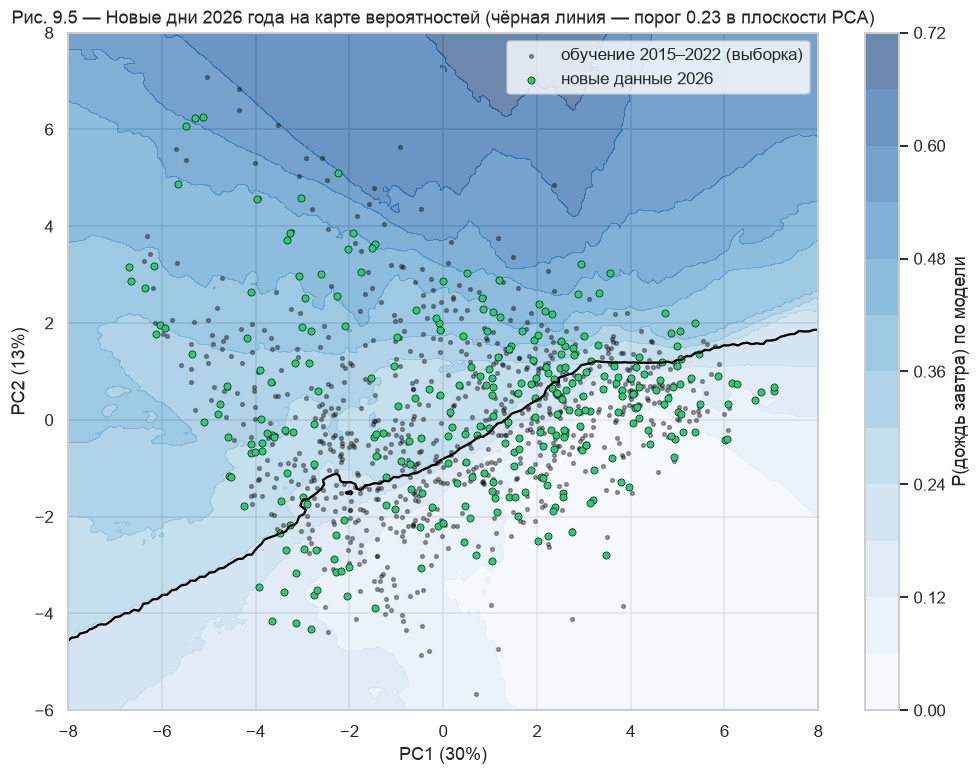

In [15]:
scaler = StandardScaler().fit(ref["X_train"])
pca = PCA(2, random_state=SEED).fit(scaler.transform(ref["X_train"]))
T2 = pca.transform(scaler.transform(ref["X_train"]))
N2 = pca.transform(scaler.transform(X_new))
gx, gy = np.meshgrid(np.linspace(-8, 8, 160), np.linspace(-6, 8, 160))
back = scaler.inverse_transform(pca.inverse_transform(np.c_[gx.ravel(), gy.ravel()]))
P = rf.predict_proba(pd.DataFrame(back, columns=FEATURES))[:, 1].reshape(gx.shape)
fig, ax = plt.subplots(figsize=(11, 8))
cs = ax.contourf(gx, gy, P, levels=12, cmap="Blues", alpha=0.6); plt.colorbar(cs, ax=ax, label="P(дождь завтра) по модели")
ax.contour(gx, gy, P, levels=[THR], colors="black", linewidths=1.5)
sub = np.random.default_rng(1).choice(len(T2), 800, replace=False)
ax.scatter(T2[sub, 0], T2[sub, 1], s=6, color="black", alpha=0.35, label="обучение 2015–2022 (выборка)")
ax.scatter(N2[:, 0], N2[:, 1], s=22, color="#2ECC71", edgecolor="black", linewidth=0.4, label="новые данные 2026")
ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})", xlim=(-8, 8), ylim=(-6, 8),
       title="Рис. 9.5 — Новые дни 2026 года на карте вероятностей (чёрная линия — порог 0.23 в плоскости PCA)")
ax.legend(loc="upper right")
save("fig_9_5_new_data_pca")

## D.4 Задание 3 — детектор дрейфа

**Детектор из материалов:** средняя евклидова дистанция новых точек до центра данных обучения в плоскости PCA сравнивается с порогом. Порог в материалах задаётся ползунком; мы выбираем его **по данным**: 99-й процентиль средней дистанции для случайных выборок того же размера из самих данных обучения (то, что «нормально» для лота из 292 дней).

Дополнительно — **проверка по каждому признаку** (критерий Колмогорова–Смирнова и PSI), причём новые данные сравниваются с теми же месяцами (январь–октябрь) обучающих лет, чтобы сезон не выдавался за дрейф. И **контрольный сценарий**: те же данные 2026 года с барометром, сдвинутым на +6 гПа (как в ноутбуке 04), — заметит ли его детектор?

In [16]:
centroid = T2.mean(0)
def mean_dist(A):
    return float(np.linalg.norm(A - centroid, axis=1).mean())
rng = np.random.default_rng(SEED)
null = np.array([mean_dist(T2[rng.choice(len(T2), len(N2), replace=False)]) for _ in range(2000)])
drift_thr = float(np.quantile(null, 0.99))

def psi(ref_v, new_v, bins=10):
    edges = np.unique(np.quantile(ref_v, np.linspace(0, 1, bins + 1)))
    r = np.histogram(np.clip(ref_v, edges[0], edges[-1]), edges)[0] / len(ref_v) + 1e-6
    n = np.histogram(np.clip(new_v, edges[0], edges[-1]), edges)[0] / len(new_v) + 1e-6
    return float(np.sum((n - r) * np.log(n / r)))

same_months = ref["X_train"][train.date.dt.month.reset_index(drop=True).between(1, 10)]

def drift_report(Xn, label):
    d = mean_dist(pca.transform(scaler.transform(Xn)))
    per = pd.DataFrame({"KS p-value": [stats.ks_2samp(same_months[f], Xn[f]).pvalue for f in FEATURES],
                        "PSI": [psi(same_months[f].to_numpy(), Xn[f].to_numpy()) for f in FEATURES]}, index=RU)
    return {"Лот": label, "Средняя дистанция до центра (PCA)": d, "Порог (99-й процентиль)": drift_thr,
            "Дрейф по PCA-детектору": "да" if d > drift_thr else "нет",
            "Признаков с PSI > 0.25": int((per.PSI > 0.25).sum()),
            "Признаков с KS p < 0.01": int((per["KS p-value"] < 0.01).sum())}, per

X_shift = X_new.copy(); X_shift["pressure_msl_mean"] += 6.0
rep_new, per_new = drift_report(X_new, "Новые данные 2026")
rep_shift, per_shift = drift_report(X_shift, "2026 + барометр +6 гПа")
rep_test, per_test = drift_report(X_te.iloc[:len(X_new)], "Контроль: тест 2024 (те же месяцы)")
display(pd.DataFrame([rep_test, rep_new, rep_shift]).set_index("Лот").round(3))
pd.DataFrame({"PSI 2026": per_new.PSI, "KS p 2026": per_new["KS p-value"], "PSI 2026 + барометр": per_shift.PSI}).sort_values("PSI 2026", ascending=False).head(8).round(3)

,Средняя дистанция до центра (PCA),Порог (99-й процентиль),Дрейф по PCA-детектору,Признаков с PSI > 0.25,Признаков с KS p < 0.01
Лот,,,,,
Контроль: тест 2024 (те же месяцы),3.175,3.213,нет,0,4
Новые данные 2026,3.407,3.213,да,1,2
2026 + барометр +6 гПа,3.408,3.213,да,2,3


,PSI 2026,KS p 2026,PSI 2026 + барометр
Влажность почвы,0.733,0.000,0.733
Доля солнечного сияния,0.144,0.000,0.144
"Максимальная влажность, %",0.108,0.556,0.108
"Облачность вчера, %",0.107,0.018,0.107
"Облачность, %",0.105,0.026,0.105
"Точка росы, °C",0.103,0.200,0.103
"Дефицит упругости пара, кПа",0.089,0.121,0.089
"Давление, гПа",0.079,0.081,0.928


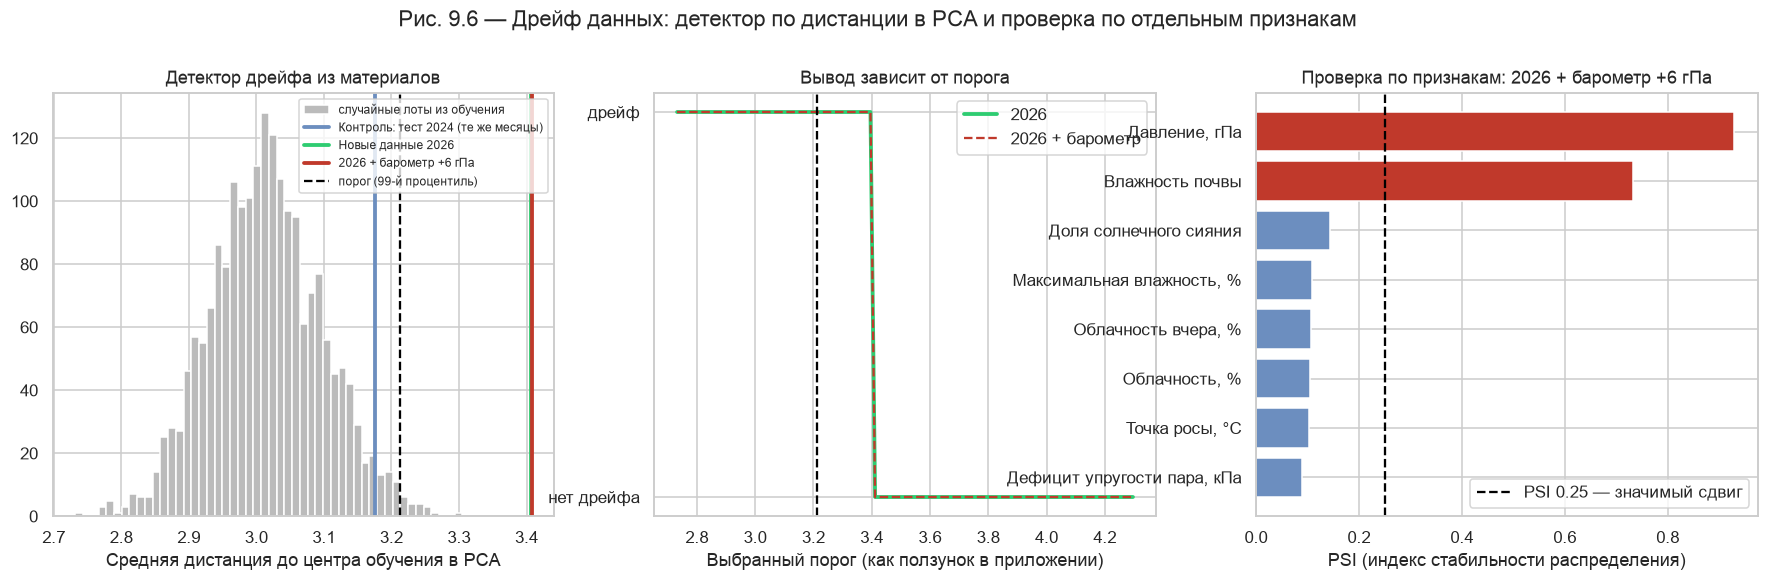

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].hist(null, bins=50, color="#BBBBBB", label="случайные лоты из обучения")
for rep, col in [(rep_test, "#6C8EBF"), (rep_new, "#2ECC71"), (rep_shift, "#C0392B")]:
    axes[0].axvline(rep["Средняя дистанция до центра (PCA)"], color=col, lw=2.5, label=rep["Лот"])
axes[0].axvline(drift_thr, color="black", ls="--", label="порог (99-й процентиль)")
axes[0].set(xlabel="Средняя дистанция до центра обучения в PCA", title="Детектор дрейфа из материалов"); axes[0].legend(fontsize=8)
thr_grid = np.linspace(null.min(), null.max() * 1.3, 100)
axes[1].plot(thr_grid, [rep_new["Средняя дистанция до центра (PCA)"] > t for t in thr_grid], color="#2ECC71", lw=2.5, label="2026")
axes[1].plot(thr_grid, [rep_shift["Средняя дистанция до центра (PCA)"] > t for t in thr_grid], color="#C0392B", ls="--", label="2026 + барометр")
axes[1].axvline(drift_thr, color="black", ls="--"); axes[1].set_yticks([0, 1], ["нет дрейфа", "дрейф"])
axes[1].set(xlabel="Выбранный порог (как ползунок в приложении)", title="Вывод зависит от порога"); axes[1].legend()
top = per_shift.PSI.sort_values().tail(8)
axes[2].barh(top.index, top.values, color=["#C0392B" if v > 0.25 else "#6C8EBF" for v in top.values])
axes[2].axvline(0.25, color="black", ls="--", label="PSI 0.25 — значимый сдвиг")
axes[2].set(xlabel="PSI (индекс стабильности распределения)", title="Проверка по признакам: 2026 + барометр +6 гПа"); axes[2].legend()
fig.suptitle("Рис. 9.6 — Дрейф данных: детектор по дистанции в PCA и проверка по отдельным признакам", y=1.03)
save("fig_9_6_drift")

**Интерпретация (рис. 9.6).**
- **Детектор из материалов** (средняя дистанция точек до центра обучения в плоскости PCA, порог — 99-й процентиль случайных лотов из обучения = 3.213):
  - контроль (2024 год, те же месяцы): 3.175 — дрейфа нет;
  - 2026 год: 3.407 — **дрейф**;
  - 2026 год + искусственный сдвиг барометра +6 гПа: 3.408 — тоже дрейф, но значение почти не изменилось.
- **Вывод зависит от порога (средняя панель):** при любом пороге ниже 3.41 2026 год объявляется дрейфом, выше — нет. При пороге ниже 3.175 дрейфом был бы объявлен и контрольный 2024 год (ложная тревога). Порог — это компромисс между ложными тревогами и пропущенным дрейфом, поэтому в приложении он задаётся ползунком.
- **Слабость детектора:** сдвиг барометра на +6 гПа (≈ 0.8 стандартного отклонения давления) он **почти не замечает** (3.407 → 3.408). Причина: две компоненты PCA сохраняют только 43 % дисперсии 26 признаков, и сдвиг одного признака в среднем расстоянии «растворяется».
- **Проверка по отдельным признакам** это исправляет: PSI давления в сценарии с барометром = 0.928 (порог значимого сдвига 0.25) — сдвиг сразу найден и указан конкретный датчик. KS-тест для этого менее удобен: на контрольном 2024 годе он даёт p < 0.01 уже по 4 признакам (на больших выборках он реагирует на любые мелкие сезонные различия).
- **Что реально сдвинулось в 2026 году:** влажность почвы (PSI 0.733, KS p ≈ 0). Это не поломка датчика, а тренд: средняя влажность почвы за январь–октябрь в годы обучения 0.263–0.316, а в 2023–2026 — 0.241–0.268 (засушливые годы).
- **Мера:** используем два уровня контроля — общий детектор (сигнал «что-то изменилось») и PSI по каждому признаку (что именно изменилось). Сделали так, **потому что** общий детектор пропускает сдвиг одного датчика, а именно это самая частая неисправность в метеосети.

## D.5 Задания 4–5 — SHAP для новых данных и сравнение SHAP / LIME для одного нового дня

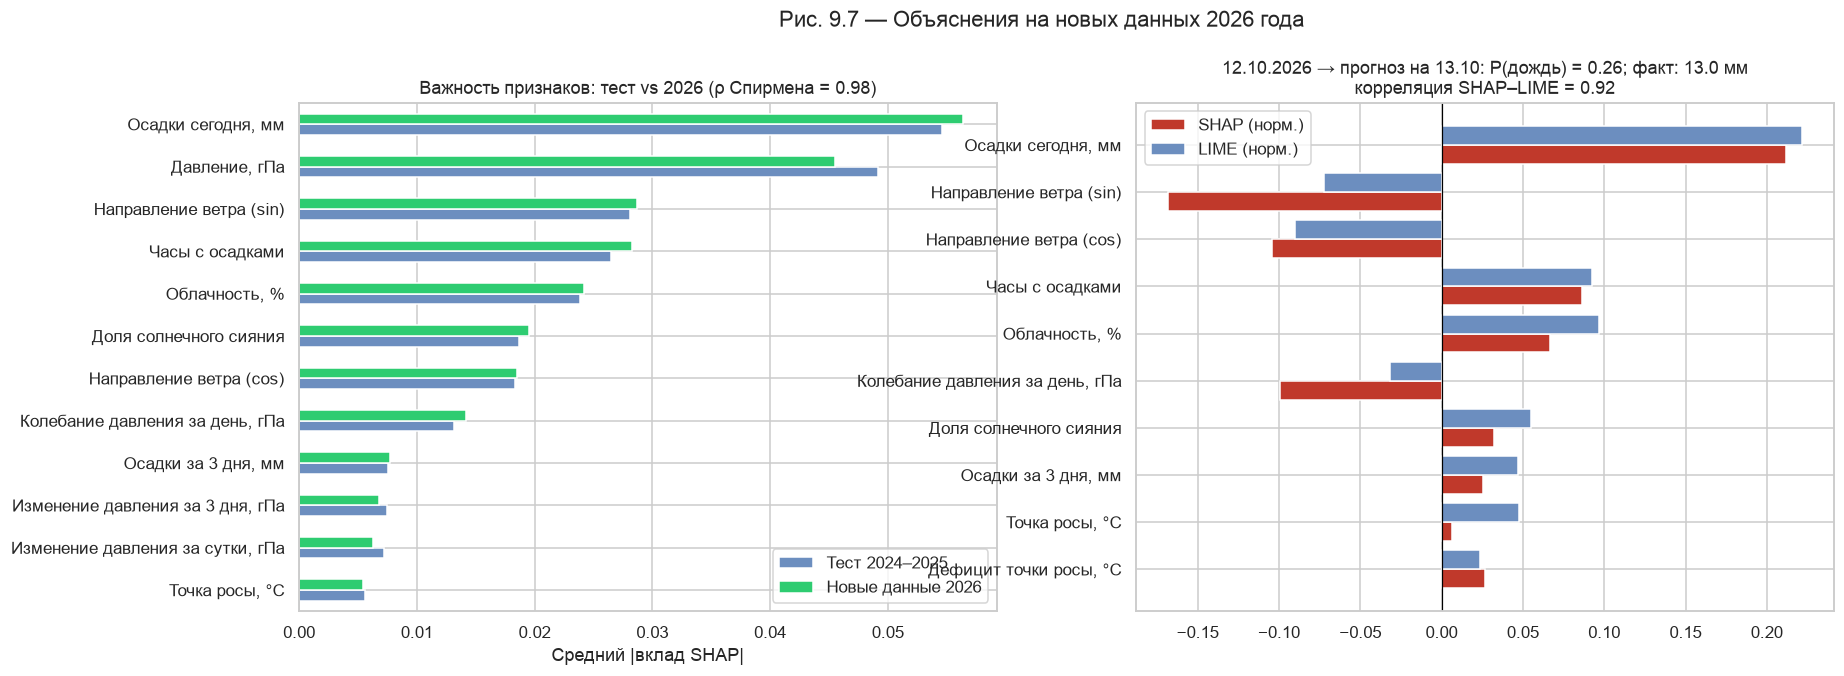

Экспорт: data/processed/new_2026_predictions.csv


In [18]:
sv_new = np.asarray(explainer.shap_values(X_new)); sv_new = sv_new[..., 1] if sv_new.ndim == 3 else sv_new
imp_cmp = pd.DataFrame({"Тест 2024–2025": np.abs(sv).mean(0), "Новые данные 2026": np.abs(sv_new).mean(0)}, index=RU)
rho_new = stats.spearmanr(imp_cmp.iloc[:, 0], imp_cmp.iloc[:, 1]).statistic
day = feats_new.index[feats_new.date == pd.Timestamp("2026-10-12")][0]
lv, e = lime_vector(X_new.iloc[day])
s = pd.Series(sv_new[day], index=RU); l = pd.Series(lv, index=RU)
c_day = np.corrcoef(s / s.abs().sum(), l / l.abs().sum())[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
top = imp_cmp.sum(1).sort_values().index[-12:]
imp_cmp.loc[top].plot(kind="barh", ax=axes[0], color=["#6C8EBF", "#2ECC71"])
axes[0].set(xlabel="Средний |вклад SHAP|", title=f"Важность признаков: тест vs 2026 (ρ Спирмена = {rho_new:.2f})")
top_d = (s.abs() + l.abs()).sort_values().index[-10:]
y = np.arange(len(top_d))
axes[1].barh(y - 0.2, (s / s.abs().sum())[top_d], 0.4, color="#C0392B", label="SHAP (норм.)")
axes[1].barh(y + 0.2, (l / l.abs().sum())[top_d], 0.4, color="#6C8EBF", label="LIME (норм.)")
axes[1].set_yticks(y, top_d); axes[1].axvline(0, color="black", lw=0.8); axes[1].legend()
real = new_raw.set_index("date").precipitation_sum.get(pd.Timestamp("2026-10-13"), np.nan)
axes[1].set_title(f"12.10.2026 → прогноз на 13.10: P(дождь) = {p_new[day]:.2f}; факт: {real:.1f} мм\nкорреляция SHAP–LIME = {c_day:.2f}")
fig.suptitle("Рис. 9.7 — Объяснения на новых данных 2026 года", y=1.02)
save("fig_9_7_new_data_xai")

out = new_raw[new_raw.date.isin(feats_new.date)].reset_index(drop=True).assign(
    **{"Прогноз (1 = дождь завтра)": pred_new, "Вероятность дождя": p_new.round(3), "Факт (1 = дождь завтра)": y_new})
out.to_csv(ROOT / "data" / "processed" / "new_2026_predictions.csv", index=False)
print("Экспорт: data/processed/new_2026_predictions.csv")

**Интерпретация (рис. 9.7).**
- **Логика модели на 2026 году не изменилась:** порядок важности признаков по SHAP почти тот же, что на тесте (ρ Спирмена = 0.98). Сдвинувшаяся влажность почвы не входит даже в 15 главных признаков, поэтому её дрейф на решения почти не влияет — это объясняет, почему F1 остался на прежнем уровне.
- **Пример 12.10.2026:** P(дождь) = 0.26 > 0.23 → «дождь завтра» (жёлтый уровень); 13 октября выпало 13.0 мм — прогноз оправдался. Главный вклад «к дождю» — осадки сегодня (и по SHAP, и по LIME), «против» — направление ветра. Методы согласны (корреляция 0.92), но расходятся по колебанию давления: SHAP даёт заметный отрицательный вклад, LIME — слабый.
- Вероятность 0.26 лежит прямо у порога — по ноутбуку 07 это **чувствительная точка**, такой прогноз в системе стоит помечать как неуверенный.

---
## Ответы на вопросы лабораторной №3

### Лист вопросов (адаптирован к нашей задаче)

**1. Какие входные признаки и что означает целевая переменная?** — У преподавателя 4 признака и цель `failure`. У нас 26 признаков суточной погоды (давление и его изменения, осадки, облачность, ветер, влажность, температура, сезон), полученных SQL-запросом из хранилища, и цель `rain_tomorrow` — будут ли завтра осадки ≥ 1 мм (аналог «аварии» — неблагоприятное событие, которое нужно предупредить).

**2. Чем прогноз класса отличается от вероятности?** — Вероятность — это оценка модели (например, 0.26 для 12.10.2026), класс — решение после сравнения с порогом (0.26 ≥ 0.23 → «дождь»). Вероятность 0.26 не означает гарантии; при другом пороге (0.5) тот же день был бы «сухим». Поэтому для пользователя важно показывать обе величины.

**3. Какой признак даёт наибольший вклад SHAP для выбранного дня?** — Для 30.05.2024 и 12.09.2024 — «осадки сегодня» (≈ +0.12 и +0.11), для 10.06.2025 — давление (≈ −0.045). В целом по тесту — тоже осадки сегодня и давление.

**4. Какие признаки влияют на объяснение LIME и как оно соотносится с SHAP?** — Те же главные признаки (давление, осадки сегодня, часы с осадками, направление ветра), но LIME выдаёт их в виде правил с порогами («давление ≤ 1011.8») и иногда меняет порядок. Корреляция с SHAP — 0.87–0.98 для трёх разобранных дней, медиана по тесту 0.92.

**5. Что даёт проекция PC1–PC2 и что теряется?** — Она позволяет увидеть, где лежат новые точки относительно обучающих, и показать карту вероятностей. Но две компоненты сохраняют только 43 % дисперсии 26 признаков: точки, близкие на плоскости, могут быть далеки в исходном пространстве, а граница решения на плоскости — лишь приближение. Именно поэтому PCA-детектор дрейфа не заметил сдвиг барометра.

**6. Что означает низкая корреляция Пирсона? Доказывает ли она ошибку модели?** — Нет. Она означает, что два метода по-разному объясняют один и тот же прогноз. Причины могут быть в самих методах: дискретизация и случайная выборка соседей у LIME, локальная линейная аппроксимация. У нас низкая корреляция встречается в основном у дней рядом с порогом, где и прогноз неуверенный. Это сигнал «проверить вручную», а не доказательство ошибки; ошибку модели показывает только сравнение с реальными исходами.

**7. Какой порог вызвал пометку FLAGGED?** — В 58 случаях из 74 — только порог разницы по признаку (> 0.15), в 16 — оба порога, только по корреляции — ни одного. Чаще всего расходится признак «осадки сегодня» (56 дней). По методу исправленной версии приложения (DEC_XAI: деление на максимум, порог 0.5) помечено 253 дня: те же 16 по корреляции плюс 237 только по разнице — там флаги получают и давление, и направление ветра, потому что разница сосредоточена у нескольких главных признаков (раздел C.2).

**8. Какие проверки нужны перед использованием прогноза в реальной системе?** — (1) проверка формата и диапазонов входа (CHECK-ограничения в хранилище); (2) контроль датчиков и сравнение с соседними станциями (ноутбук 04); (3) детектор дрейфа + PSI по каждому признаку; (4) пометка неуверенных прогнозов у порога и FLAGGED-дней; (5) регулярная проверка на реальных исходах и сравнение с инерционным прогнозом; (6) переобучение при устойчивом падении качества.

### Шесть заданий «приложения с новыми данными»

| Задание | Что сделано | Результат |
|---|---|---|
| 1. Прогноз | Загружен CSV 2026 года, проверены столбцы, получены класс и вероятность | 292 дня, 125 тревог; 12.10.2026: P = 0.26 → «дождь», выпало 13 мм |
| 2. Границы решений | Новые точки на карте вероятностей PCA | все внутри облака обучения, экстраполяции нет |
| 3. Дрейф | Порог детектора изменён ползунком | при пороге < 3.41 — «дрейф», выше — «нет»; ниже 3.175 ложно срабатывает даже на контроле; PSI указывает на влажность почвы |
| 4. SHAP | Сводный график по новому лоту | те же главные признаки, ρ = 0.98 с тестом |
| 5. SHAP и LIME | Сравнение для одного дня | 12.10.2026: корреляция 0.92, совпадает главный признак и направления |
| 6. Реальная проверка | Сравнение с фактическими осадками | ROC-AUC 0.722 (тест 0.793), F1 0.513 (0.519), лучше инерционного прогноза (0.43) |

**Хватит ли Excel для анализа экспорта?** — Для фильтрации, сортировки и сводных таблиц по 730 дням — да, поэтому таблицы выгружены в CSV (`xai_shap_lime_detail.csv`, `xai_shap_lime_summary.csv`, `new_2026_predictions.csv`). Но пересчитать SHAP, LIME или дрейф Excel не может — для этого нужен код; приложение показывает объяснение конкретного дня в контексте, а Excel — для документирования и выборочной проверки.

### Главный вопрос лабораторной: достаточно ли доказательств, чтобы доверять прогнозу на новых данных?

Для 2026 года — **да, с оговорками**. В пользу доверия: формат данных совпадает, новые точки внутри области обучения, логика модели (SHAP) не изменилась, а реальная проверка подтвердила рабочее качество (F1 0.513). Против безусловного доверия: детектор нашёл дрейф (влажность почвы), ROC-AUC снизился до 0.722, качество неравномерно по месяцам, а прогнозы у порога и FLAGGED-дни неустойчивы. Поэтому модель можно использовать **вместе с контролем**: мониторинг дрейфа по признакам, пометка неуверенных прогнозов и периодическая проверка на реальных исходах. Доверие к модели даёт проверка, а не сам прогноз.